## 1. Data Cleaning Pipeline — Mouad

I created cleaning functions to handle some of the main problems in the Walmart transaction data. These include duplicate records, inconsistent store IDs, mixed timestamp formats, prices stored as text, negative quantities, and inconsistent product categories.

My goal was to clean the data without removing more information than necessary. For example, I removed exact duplicates but kept transactions with missing timestamps or negative quantities and flagged them for further review. I also kept the original columns so we can compare the cleaned values with the raw data later.

I standardized the categories so different labels for the same general category can be grouped together. Based on Wednesday's Weather API Studio, I also normalized the timestamps into daily dates so our transaction data can be joined with weather data more easily.

These cleaning functions will help the rest of the team analyze demand, compare stores, and investigate whether unusual sales patterns are real or caused by data issues.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import display

# Find the team repository
REPO_NAME = "F26-DS2002-Midterm-Repo-Nate-Mohamed-Mouad"

def find_repo_root():
    here = Path.cwd()

    folders = [
        here,
        *here.parents,
        Path("/content") / REPO_NAME
    ]

    for folder in folders:
        if (
                (folder / "CHARTER.md").is_file()
                and (folder / "data" / "walmart_transactions.csv").is_file()
        ):
            return folder

    raise FileNotFoundError(
        "Team repository not found. Open this notebook "
        "from your cloned repo or clone the repo into Colab."
    )


REPO_ROOT = find_repo_root()

def find_data(filename):
    path = REPO_ROOT / "data" / filename

    if not path.is_file():
        raise FileNotFoundError(filename)

    return path


# Load the transaction and store files
raw = pd.read_csv(
    find_data("walmart_transactions.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

stores_raw = pd.read_csv(
    find_data("store_locations.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

print("Original transactions:", len(raw))
print("Store reference rows:", len(stores_raw))


# Standardize store IDs
def clean_store_id(series):
    return (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(
            r"^FL[-_\s]*(\d+)$",
            r"FL-\1",
            regex=True
        )
    )


# Parse different timestamp formats
def clean_dates(series):
    formats = [
        "%Y-%m-%dT%H:%M:%S",
        "%Y-%m-%d %H:%M:%S",
        "%Y-%m-%d %H:%M",
        "%m/%d/%Y %H:%M",
        "%m/%d/%Y %H:%M:%S",
        "%m-%d-%Y %H:%M:%S",
        "%m-%d-%Y %H:%M",
        "%d-%b-%Y %H:%M",
        "%d-%b-%Y %H:%M:%S"
    ]

    result = pd.Series(
        pd.NaT,
        index=series.index,
        dtype="datetime64[ns]"
    )

    for fmt in formats:
        parsed = pd.to_datetime(
            series,
            format=fmt,
            errors="coerce"
        )

        result = result.fillna(parsed)

    return result


# Standardize category labels
CATEGORY_ALIASES = {
    "Alcoholic Beverages": "Alcohol",
    "Baby Products": "Baby",
    "Breakfast Foods": "Breakfast",
    "Emergency Supplies": "Emergency",
    "Games & Entertainment": "Entertainment",
    "Groceries": "Grocery",
    "Health & Wellness": "Health",
    "Household Essentials": "Household"
}


def clean_category(series):
    return (
        series.astype("string")
        .str.strip()
        .str.title()
        .replace(CATEGORY_ALIASES)
    )


# Main transaction cleaning function
def clean_transactions(df):
    cleaned = df.copy()
    log = []

    # 1. Remove exact duplicate rows
    before = len(cleaned)
    cleaned = cleaned.drop_duplicates().copy()

    log.append({
        "dataset": "transactions",
        "step": "Remove exact duplicates",
        "before": before,
        "after": len(cleaned),
        "affected": before - len(cleaned)
    })

    # Helper for logging steps that do not remove rows
    def log_step(step, affected):
        log.append({
            "dataset": "transactions",
            "step": step,
            "before": len(cleaned),
            "after": len(cleaned),
            "affected": int(affected)
        })

    # 2. Standardize store IDs
    cleaned["store_id_clean"] = clean_store_id(
        cleaned["store_id"]
    )

    changed_stores = (
            cleaned["store_id"].astype("string")
            != cleaned["store_id_clean"]
    ).fillna(False).sum()

    log_step("Standardize store IDs", changed_stores)

    # 3. Parse timestamps
    cleaned["timestamp_clean"] = clean_dates(
        cleaned["timestamp"]
    )

    # Create daily dates for the weather join
    cleaned["date"] = (
        cleaned["timestamp_clean"].dt.normalize()
    )

    log_step(
        "Parse nonmissing timestamps",
        cleaned["timestamp_clean"].notna().sum()
    )

    log_step(
        "Flag missing / unparseable timestamps",
        cleaned["timestamp_clean"].isna().sum()
    )

    log_step(
        "Create daily date keys",
        cleaned["date"].notna().sum()
    )

    # 4. Convert prices into numeric values
    price_text = cleaned["unit_price"].astype("string")

    formatted_prices = price_text.str.contains(
        r"\$|^\s|\s$",
        regex=True,
        na=False
    ).sum()

    cleaned["unit_price_clean"] = pd.to_numeric(
        price_text
        .str.strip()
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    log_step(
        "Clean formatted unit prices",
        formatted_prices
    )

    log_step(
        "Flag missing/unparseable unit prices",
        cleaned["unit_price_clean"].isna().sum()
    )

    # 5. Convert quantities and flag possible returns
    cleaned["quantity_clean"] = pd.to_numeric(
        cleaned["quantity"],
        errors="coerce"
    )

    cleaned["possible_return"] = (
            cleaned["quantity_clean"] < 0
    )

    log_step(
        "Flag negative quantities",
        cleaned["possible_return"].sum()
    )

    log_step(
        "Flag missing/unparseable quantities",
        cleaned["quantity_clean"].isna().sum()
    )

    # 6. Standardize SKUs
    cleaned["sku_clean"] = (
        cleaned["sku"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    changed_skus = (
            cleaned["sku"].astype("string")
            != cleaned["sku_clean"]
    ).fillna(False).sum()

    log_step(
        "Standardize SKU formatting",
        changed_skus
    )

    # 7. Standardize categories
    cleaned["category_clean"] = clean_category(
        cleaned["category"]
    )

    changed_categories = (
            cleaned["category"].astype("string")
            != cleaned["category_clean"]
    ).fillna(False).sum()

    log_step(
        "Standardize category formatting and aliases",
        changed_categories
    )

    return cleaned, pd.DataFrame(log)


Original transactions: 25562
Store reference rows: 14


In [2]:
# Run the cleaning function
clean, decision_log = clean_transactions(raw)


# Standardize the store reference data
stores_clean = stores_raw.copy()

stores_clean["store_id_clean"] = clean_store_id(
    stores_clean["store_id"]
)

# Check that store aliases do not have conflicting details
conflicts = stores_clean.groupby("store_id_clean")[
    ["city", "state", "latitude", "longitude"]
].nunique(dropna=True)

assert not conflicts.gt(1).any().any(), (
    "Conflicting store information was found."
)

# Remove duplicate store aliases
stores_clean = stores_clean.drop_duplicates(
    subset="store_id_clean"
).copy()

# Add the store-reference decision to the log
store_log = pd.DataFrame([{
    "dataset": "store_locations",
    "step": "Consolidate duplicate store ID aliases",
    "before": len(stores_raw),
    "after": len(stores_clean),
    "affected": len(stores_raw) - len(stores_clean)
}])

decision_log = pd.concat(
    [decision_log, store_log],
    ignore_index=True
)


# Show cleaning results
print("Original transactions:", len(raw))
print("Cleaned transactions:", len(clean))
print("Rows removed:", len(raw) - len(clean))

print("Unique cleaned stores:",
      clean["store_id_clean"].nunique())

print("Original category labels:",
      raw["category"].nunique())

print("Cleaned category labels:",
      clean["category_clean"].nunique())

print("\nCleaning decision log:")
display(decision_log)


# Verify that the correct number of duplicates was removed
assert len(clean) == (
        len(raw) - raw.duplicated().sum()
)

assert not clean.duplicated(
    subset=raw.columns.tolist()
).any()

# Check numeric columns
assert clean["unit_price_clean"].notna().all(), (
    "Some prices are missing or could not be converted."
)

assert clean["quantity_clean"].notna().all(), (
    "Some quantities are missing or could not be converted."
)

# Confirm stores match the reference file
assert clean["store_id_clean"].isin(
    stores_clean["store_id_clean"]
).all(), "Some store IDs did not match."

# Check timestamp parsing
assert (
        clean["timestamp_clean"].isna().sum()
        == clean["timestamp"].isna().sum()
), "Some nonmissing timestamps failed to parse."

# Check date format for weather analysis
assert pd.api.types.is_datetime64_any_dtype(
    clean["date"]
)

assert clean.loc[
    clean["date"].notna(), "date"
].dt.hour.eq(0).all()

print("\nAll initial cleaning checks passed!")


# Check the transaction timeline
daily_orders = (
    clean.dropna(subset=["date"])
    .groupby("date")
    .size()
)

print("\nFirst sales date:",
      daily_orders.index.min().date())

print("Last sales date:",
      daily_orders.index.max().date())

print("Peak daily order date:",
      daily_orders.idxmax().date())

print("Peak daily transaction records:",
      int(daily_orders.max()))

Original transactions: 25562
Cleaned transactions: 25532
Rows removed: 30
Unique cleaned stores: 12
Original category labels: 37
Cleaned category labels: 10

Cleaning decision log:


,dataset,step,before,after,affected
0,transactions,Remove exact duplicates,25562,25532,30
1,transactions,Standardize store IDs,25532,25532,4345
2,transactions,Parse nonmissing timestamps,25532,25532,24648
3,transactions,Flag missing / unparseable timestamps,25532,25532,884
4,transactions,Create daily date keys,25532,25532,24648
5,transactions,Clean formatted unit prices,25532,25532,4329
6,transactions,Flag missing/unparseable unit prices,25532,25532,0
7,transactions,Flag negative quantities,25532,25532,130
8,transactions,Flag missing/unparseable quantities,25532,25532,0
9,transactions,Standardize SKU formatting,25532,25532,0



All initial cleaning checks passed!

First sales date: 2024-09-01
Last sales date: 2024-09-30
Peak daily order date: 2024-09-14
Peak daily transaction records: 2007


## 2. Cleaning Decision Log

I started a decision log to keep track of what we cleaned, how many rows were affected, and why we made each change. My main goal was to avoid deleting data unless there was a clear reason to.

For example, I removed exact duplicates because they could cause us to count the same transaction more than once. However, I kept negative quantities and missing timestamps because we don't know for sure if those are errors.

The cleaning function generates a table showing the row counts before and after each step, along with how many records were affected. This allows us to verify our decisions using the actual dataset.

| Problem | Decision | Reason |
|---|---|---|
| Duplicate transactions | Remove exact duplicates | Counting the same transaction twice could inflate sales. |
| Inconsistent store IDs | Standardize capitalization, spaces, and separators | Different versions of the same store ID could cause incorrect joins. |
| Duplicate store records | Consolidate matching store ID aliases after checking their information | Prevents the store join from duplicating transaction records. |
| Missing or mixed-format timestamps | Parse the dates, keep missing values, and create daily date keys | We shouldn't guess when purchases happened. Daily analysis can exclude undated rows. |
| Prices stored as text | Remove dollar signs and extra spaces, then convert to numeric | Numeric prices are necessary for revenue calculations. |
| Negative quantities | Keep and flag them as possible returns or errors | We shouldn't assume every negative quantity is incorrect or automatically delete it. |
| Inconsistent SKUs | Standardize formatting while preserving original SKU values | This prepares the data for product consolidation without losing the original codes. |
| Inconsistent categories | Standardize capitalization and known category aliases | Different labels for the same category could distort category-level demand analysis. |

## 3. SKU Consolidation — Pop-Tarts First

For the SKU mapping, I started with Strawberry Pop-Tarts because the product catalog lists the same general product under four different SKU codes. If we analyze each code separately, we could miss part of the total demand for that product.

I created a mapping table that groups the four codes under the Strawberry Pop-Tarts product family while still keeping their original SKUs.

One issue I noticed is that the package sizes are not all the same. Three SKUs describe four-packs, while one describes a six-pack. Because of this, I don't want to treat all four SKUs as identical units without accounting for package size.

For now, the mapping groups these SKUs into one proposed product family while preserving their differences for later analysis. I also calculated how many catalog SKUs have been mapped so far and how many still need to be reviewed.

In [3]:
# Load the product catalog
products = pd.read_csv(
    find_data("product_catalog.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

# Standardize product SKUs and categories
products["sku_clean"] = (
    products["sku"]
    .astype("string")
    .str.strip()
    .str.upper()
)

products["category_clean"] = clean_category(
    products["category"]
)

# Each catalog SKU should have one reference record
assert products["sku_clean"].is_unique, (
    "Duplicate cleaned SKUs found in product catalog."
)


# Start SKU mapping with Strawberry Pop-Tarts
pop_tarts_mapping = pd.DataFrame({
    "sku_clean": [
        "PT-12",
        "SKU#459812",
        "POPTART-STRAW",
        "PT_STRAWBERRY"
    ],
    "product_family": [
                          "Strawberry Pop-Tarts"
                      ] * 4
})


# Preserve information from the product catalog
pop_tarts_mapping = pop_tarts_mapping.merge(
    products[[
        "sku_clean",
        "product_name",
        "package_size",
        "category_clean"
    ]],
    on="sku_clean",
    how="left",
    validate="one_to_one"
)


# Check that all four SKUs were matched
assert len(pop_tarts_mapping) == 4

assert pop_tarts_mapping["sku_clean"].is_unique

assert pop_tarts_mapping["product_name"].notna().all(), (
    "Some Pop-Tarts SKUs were not found in the catalog."
)


# Extract numerical package counts
# Examples: "4-pack", "4pk", and "6 pack"
pop_tarts_mapping["pack_count"] = pd.to_numeric(
    pop_tarts_mapping["package_size"]
    .astype("string")
    .str.extract(r"(\d+)", expand=False),
    errors="coerce"
)

assert pop_tarts_mapping["pack_count"].notna().all()


# Build a provisional catalog mapping
# Unmapped SKUs remain separate for now
family_lookup = pop_tarts_mapping.set_index(
    "sku_clean"
)["product_family"]

catalog_progress = products.copy()

catalog_progress["canonical_product"] = (
    catalog_progress["sku_clean"]
    .map(family_lookup)
    .fillna(catalog_progress["sku_clean"])
)


# Find the largest consolidated group
group_sizes = (
    catalog_progress
    .groupby("canonical_product")["sku_clean"]
    .nunique()
    .sort_values(ascending=False)
)


# Show SKU mapping progress
print("Starting distinct catalog SKUs:",
      products["sku_clean"].nunique())

print("SKUs mapped into Pop-Tarts family:",
      pop_tarts_mapping["sku_clean"].nunique())

print("Explicitly mapped product families:",
      pop_tarts_mapping["product_family"].nunique())

print("Provisional canonical product groups:",
      catalog_progress["canonical_product"].nunique())

print("Largest consolidated group:",
      group_sizes.idxmax())

print("SKUs in largest group:",
      int(group_sizes.max()))

print("Remaining unmapped SKUs:",
      products["sku_clean"].nunique()
      - pop_tarts_mapping["sku_clean"].nunique())


print("\nPop-Tarts SKU mapping:")
display(pop_tarts_mapping)

print("\nPackage-size differences present:",
      pop_tarts_mapping["pack_count"].nunique() > 1)

Starting distinct catalog SKUs: 45
SKUs mapped into Pop-Tarts family: 4
Explicitly mapped product families: 1
Provisional canonical product groups: 42
Largest consolidated group: Strawberry Pop-Tarts
SKUs in largest group: 4
Remaining unmapped SKUs: 41

Pop-Tarts SKU mapping:


,sku_clean,product_family,product_name,package_size,category_clean,pack_count
0,PT-12,Strawberry Pop-Tarts,pop-tarts strawberry,4-pack,Breakfast,4
1,SKU#459812,Strawberry Pop-Tarts,Strawberry Pop-Tart,4pk,Breakfast,4
2,POPTART-STRAW,Strawberry Pop-Tarts,Pop-Tarts Strawberry,6 pack,Breakfast,6
3,PT_STRAWBERRY,Strawberry Pop-Tarts,pop-tarts strawberry,4 pack,Breakfast,4



Package-size differences present: True


In [4]:
# Get positive transactions for the mapped Pop-Tarts SKUs
pop_sales = clean.loc[
    clean["sku_clean"].isin(
        pop_tarts_mapping["sku_clean"]
    )
    & clean["quantity_clean"].gt(0)
    ].copy()


# Calculate positive reported quantities by SKU
sku_totals = (
    pop_sales
    .groupby("sku_clean")["quantity_clean"]
    .sum()
    .reindex(
        pop_tarts_mapping["sku_clean"],
        fill_value=0
    )
    .sort_values(ascending=False)
)

print("Positive reported quantities by SKU:")
display(
    sku_totals.to_frame("quantity_sold")
)

print("Combined reported quantity:",
      int(sku_totals.sum()))

print("Number of mapped SKUs:",
      len(sku_totals))


# Separate dated and undated sales
pop_dated = pop_sales.dropna(
    subset=["date"]
).copy()

undated_quantity = pop_sales.loc[
    pop_sales["date"].isna(),
    "quantity_clean"
].sum()

print("\nQuantity with valid sales dates:",
      int(pop_dated["quantity_clean"].sum()))

print("Quantity with missing dates:",
      int(undated_quantity))


# Create the initial daily SKU comparison
daily_fragmented = pop_dated.pivot_table(
    index="date",
    columns="sku_clean",
    values="quantity_clean",
    aggfunc="sum",
    fill_value=0
)

# Keep all four mapped SKU columns
daily_fragmented = daily_fragmented.reindex(
    columns=pop_tarts_mapping["sku_clean"],
    fill_value=0
)

# Combine the four SKU quantities by day
daily_fragmented[
    "Strawberry Pop-Tarts (combined)"
] = daily_fragmented.sum(axis=1)


print("\nInitial daily sales comparison:")
display(daily_fragmented.head(10))

print(
    "\nNote: Quantities are reported SKU units, "
    "not adjusted for different package sizes."
)

Positive reported quantities by SKU:


,quantity_sold
sku_clean,
PT-12,1381
POPTART-STRAW,1300
PT_STRAWBERRY,1262
SKU#459812,1255


Combined reported quantity: 5198
Number of mapped SKUs: 4

Quantity with valid sales dates: 5005
Quantity with missing dates: 193

Initial daily sales comparison:


sku_clean,PT-12,SKU#459812,POPTART-STRAW,PT_STRAWBERRY,Strawberry Pop-Tarts (combined)
date,,,,,
2024-09-01,16,15,24,18,73
2024-09-02,34,17,14,14,79
2024-09-03,28,8,12,22,70
2024-09-04,17,15,19,13,64
2024-09-05,33,43,31,44,151
2024-09-06,33,51,33,40,157
2024-09-07,48,50,41,38,177
2024-09-08,35,43,43,43,164
2024-09-09,32,28,30,60,150



Note: Quantities are reported SKU units, not adjusted for different package sizes.


In [5]:
# Verify the Pop-Tarts mapping
assert pop_tarts_mapping["sku_clean"].nunique() == 4

assert (
        pop_tarts_mapping["product_family"].nunique() == 1
)

# Consolidation should not change total reported quantity
assert sku_totals.sum() == (
    pop_sales["quantity_clean"].sum()
)

# Daily consolidation should preserve dated quantities
assert (
        daily_fragmented[
            "Strawberry Pop-Tarts (combined)"
        ].sum()
        == pop_dated["quantity_clean"].sum()
)

# Dated and undated quantities must reconcile
assert (
        pop_dated["quantity_clean"].sum()
        + undated_quantity
        == pop_sales["quantity_clean"].sum()
)


# Verify that transaction SKUs exist in the catalog
catalog_reference = products[[
    "sku_clean",
    "category_clean"
]].rename(columns={
    "category_clean": "catalog_category_clean"
})

validated = clean.merge(
    catalog_reference,
    on="sku_clean",
    how="left",
    validate="many_to_one",
    indicator=True
)

assert len(validated) == len(clean), (
    "Catalog join changed the number of transactions."
)

unmatched_skus = (
        validated["_merge"] == "left_only"
).sum()

category_mismatches = (
    validated["category_clean"]
    .ne(validated["catalog_category_clean"])
    .fillna(False)
).sum()

print("Transactions with unmatched SKUs:",
      int(unmatched_skus))

print("Transaction/category disagreements:",
      int(category_mismatches))

assert unmatched_skus == 0, (
    "Some transaction SKUs are missing from the catalog."
)

if category_mismatches > 0:
    print(
        "Review category disagreements before "
        "using categories in the final analysis."
    )


print("\nAll SKU mapping checks passed!")


# Save the decision log and starter mapping
output_path = REPO_ROOT / "data"

decision_log.to_csv(
    output_path / "decision_log_week1.csv",
    index=False
)

pop_tarts_mapping.to_csv(
    output_path / "sku_mapping_DRAFT.csv",
    index=False
)

print("Decision log saved.")
print("SKU mapping saved.")

Transactions with unmatched SKUs: 0
Transaction/category disagreements: 0

All SKU mapping checks passed!
Decision log saved.
SKU mapping saved.


### Initial SKU Mapping Findings

I started with 45 distinct SKUs in the product catalog and mapped four Strawberry Pop-Tarts SKUs into one proposed product family. With the other SKUs still treated separately, this leaves 42 provisional product groups. This isn't the final consolidation since the remaining products still need to be reviewed.

I also calculated the reported positive quantities for each of the four Pop-Tarts SKUs and combined them to show the total quantity associated with that product family. This helps show why SKU consolidation matters, since looking at just one code could underestimate demand for the overall product.

For the daily analysis, I excluded transactions with missing timestamps because we can't determine which day those purchases occurred. I kept those transactions in the overall cleaned dataset so they aren't lost entirely.

One limitation is that the four Pop-Tarts SKUs don't all have the same package size. Three describe four-packs and one describes a six-pack, so combining their quantities directly doesn't mean we're comparing identical amounts of product. I kept the package information in the mapping table so we can account for these differences later.

## 4. Weather API and Join — Mohamed

I pull daily precipitation and max wind speed from the Open-Meteo archive API for Orlando and join it to our daily order counts. The call has a timeout, retries on 429/5xx errors with backoff, and converts `time` to a datetime named `date` inside the function. It also adds a `source` column so we always know where the weather came from.

**Timezone:** the weather is requested with `timezone=America/New_York`, so each `date` is a local calendar day. Sales timestamps have no timezone, so Mouad's cleaning step cuts them to midnight (`date`) and we merge on that column.

**Decisions:**
- Left join from sales, so no sales day disappears. The `indicator=True` column and three asserts check the row count, `right_only` rows, and the orders total.
- The rows with no timestamp cannot be placed on a day, so they are excluded from the daily series and counted below.
- One location (Orlando) is used for the whole state. This keeps the join simple, but it ignores local weather at the other stores.

In [6]:
import time
import requests
import numpy as np
import matplotlib.pyplot as plt

BASE = "https://archive-api.open-meteo.com/v1/archive"
RETRY_STATUSES = {429, 500, 502, 503, 504}


def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": start, "end_date": end,
        "daily": "precipitation_sum,windspeed_10m_max",
        "timezone": "America/New_York"
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue

        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue

        r.raise_for_status()

        frame = pd.DataFrame(r.json()["daily"]).rename(
            columns={"time": "date"}
        )
        frame["date"] = pd.to_datetime(frame["date"])
        frame["source"] = "open-meteo"
        return frame


weather = daily_weather("2024-09-01", "2024-09-30")
print("weather_api_rows:", len(weather), "| source:", weather["source"].iloc[0])
display(weather.head())


# Join weather onto daily orders
weather_daily_orders = (
    clean.dropna(subset=["date"])
    .groupby("date").size()
    .rename("orders").reset_index()
)

weather_merged = weather_daily_orders.merge(
    weather, on="date", how="left", indicator=True
)

assert len(weather_merged) == len(weather_daily_orders), "the join changed the row count"
assert not (weather_merged["_merge"] == "right_only").any()
assert weather_merged["orders"].sum() == weather_daily_orders["orders"].sum(), "the orders total changed"

print("undated rows excluded from the daily series:", clean["date"].isna().sum())
print(weather_merged["_merge"].value_counts().to_string())
print("sales days with no weather:", (weather_merged["_merge"] == "left_only").sum())

weather_api_rows: 30 | source: open-meteo


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo


undated rows excluded from the daily series: 884
_merge
both          30
left_only      0
right_only     0
sales days with no weather: 0


### Q3 — Weather correlation and lag

Correlations use every day that has a matching weather day (n is printed), not a short window, because a correlation on three points can be almost anything.

**Lag convention:** lag *k* compares orders on day *t* with the weather on day *t + k*. A negative lag means the weather came first and orders followed it. A positive lag means orders came first and the weather followed. Because we try several lags, the strongest one is a lead to check, not proof.

In [7]:
LANDFALL = pd.Timestamp("2024-09-26")

lag_rows = []
for k in range(-7, 6):
    row = {"lag_days": k}
    for col, label in [("windspeed_10m_max", "wind_r"), ("precipitation_sum", "rain_r")]:
        shifted = weather_merged[col].shift(-k)
        ok = shifted.notna()
        row[label] = round(weather_merged.loc[ok, "orders"].corr(shifted[ok]), 2)
        row["n_" + label[:-2]] = int(ok.sum())
    lag_rows.append(row)

lag_table = pd.DataFrame(lag_rows).set_index("lag_days")
display(lag_table)

peak_day = weather_merged.loc[weather_merged["orders"].idxmax(), "date"]
wind_day = weather_merged.loc[weather_merged["windspeed_10m_max"].idxmax(), "date"]
rain_day = weather_merged.loc[weather_merged["precipitation_sum"].idxmax(), "date"]
baseline = weather_merged.loc[weather_merged["date"] <= "2024-09-04", "orders"].mean()

print("peak order day:      ", peak_day.date(), "|", int(weather_merged["orders"].max()), "orders")
print("baseline (Sept 1-4): ", round(baseline), "orders/day")
print("peak vs baseline:    ", round(weather_merged["orders"].max() / baseline, 1), "x")
print("landfall:            ", LANDFALL.date(), "| days from peak to landfall:", (LANDFALL - peak_day).days)
print("strongest wind day:  ", wind_day.date(), "|", weather_merged["windspeed_10m_max"].max(), "km/h")
print("heaviest rain day:   ", rain_day.date(), "|", weather_merged["precipitation_sum"].max(), "mm")
print("heaviest rain to peak orders:", (peak_day - rain_day).days, "days")

,wind_r,n_wind,rain_r,n_rain
lag_days,,,,
-7,-0.04,23,0.29,23
-6,-0.17,24,0.66,24
-5,-0.30,25,0.69,25
-4,-0.27,26,0.40,26
-3,-0.24,27,0.38,27
-2,-0.28,28,0.27,28
-1,-0.31,29,-0.00,29
0,-0.24,30,0.01,30
1,-0.26,29,-0.03,29


peak order day:       2024-09-14 | 2007 orders
baseline (Sept 1-4):  580 orders/day
peak vs baseline:     3.5 x
landfall:             2024-09-26 | days from peak to landfall: 12
strongest wind day:   2024-09-26 | 48.8 km/h
heaviest rain day:    2024-09-08 | 94.7 mm
heaviest rain to peak orders: 6 days


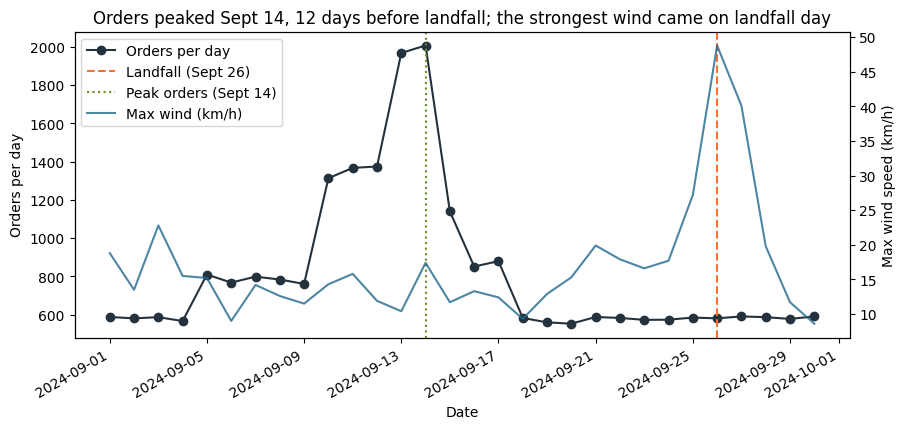

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(weather_merged["date"], weather_merged["orders"],
        marker="o", color="#24323E", label="Orders per day")
ax.axvline(LANDFALL, color="#F67132", linestyle="--", label="Landfall (Sept 26)")
ax.set_xlabel("Date")
ax.set_ylabel("Orders per day")

ax2 = ax.twinx()
ax2.plot(weather_merged["date"], weather_merged["windspeed_10m_max"],
         color="#21688D", alpha=0.8, label="Max wind (km/h)")
ax2.set_ylabel("Max wind speed (km/h)")

ax.axvline(peak_day, color="#6B8E23", linestyle=":", label="Peak orders (Sept 14)")
ax.set_title("Orders peaked Sept 14, 12 days before landfall; the strongest wind came on landfall day")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
fig.autofmt_xdate()
plt.show()

### Weather findings and limits

**Finding:** in this data, order volume does not follow Hurricane Helene's wind. Orders ran at about 580 a day (Sept 1-4), rose to a peak of 2,007 on **Sept 14** (about 3.5x baseline), and were back near baseline by Sept 18. Landfall was **Sept 26**, 12 days after the peak, and the strongest wind (48.8 km/h) arrived on landfall day, when orders were already normal. Wind and orders are weakly negatively correlated at every lag from -5 to +5 days (r between -0.33 and -0.23), so the peak in purchasing came well before the storm and was not tied to the wind.

**Closest link:** the heaviest rain in the month (93.7 mm) fell on **Sept 8**, six days before the order peak. Orders correlate with rainfall 5-6 days earlier at about r = 0.66-0.70 (n = 24-25 days). In plain terms, people may have been stocking up after a heavy rain event rather than after the hurricane itself.

**Limits:**
- That rain link rests on a single rain event and on a short series of about 25 days. We also tested many lags, so the strongest one can look better than it is. Treat it as a lead for the team to check, not as proof of cause.
- One location (Orlando) stands in for every store, so it can miss local weather.
- The 884 rows with no timestamp are excluded from the daily series.
- Weather data is shown as the API returned it (`source = open-meteo`).

## Q1 — Demand surge — Nathaniel (Nate)

I measure demand as **positive reported SKU units per calendar day**, not transaction rows or revenue. Mixed package sizes mean these are purchased packages/units as recorded, not a common physical volume. Negative quantities remain in `clean`; I exclude them from gross demand and also check signed net units. Undated rows cannot enter a daily comparison.

All boundaries below are inclusive, in September 2024. The **baseline is September 1–4**, the initial quiet period used in Q3. The **observed surge window is September 10–14**, the elevated block leading to the peak; it is selected after inspecting the series, so it describes this sample rather than predicting a storm. The **actual pre-landfall window is September 19–25**, the seven complete days before September 26. Daily means account for unequal window lengths. A September 1–7 alternative baseline tests sensitivity; it includes the initial rise and therefore lowers the multiple. Four baseline days cannot control for weekday or seasonal effects.

Helene made landfall late September 26 near **30.0° N, 83.7° W**, according to the [NHC landfall update](https://www.nhc.noaa.gov/archive/2024/al09/al092024.update.09270318.shtml). The early spike must not automatically be labeled hurricane demand.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

q1_days = pd.date_range("2024-09-01", "2024-09-30", freq="D")
q1_windows = {
    "Baseline": ("2024-09-01", "2024-09-04"),
    "Observed surge": ("2024-09-10", "2024-09-14"),
    "Pre-landfall": ("2024-09-19", "2024-09-25"),
}
q1_dated = clean.dropna(subset=["date"]).copy()
assert q1_dated["date"].between(q1_days.min(), q1_days.max()).all()
q1_sales = q1_dated.loc[q1_dated["quantity_clean"] > 0].copy()
q1_daily = q1_sales.groupby("date")["quantity_clean"].sum().reindex(q1_days, fill_value=0)
q1_net = q1_dated.groupby("date")["quantity_clean"].sum().reindex(q1_days, fill_value=0)
assert q1_daily.sum() == q1_sales["quantity_clean"].sum()
q1_summary = pd.DataFrame([
    {"window": label, "start": start, "end": end,
     "days": len(q1_daily.loc[start:end]),
     "positive_units_per_day": q1_daily.loc[start:end].mean(),
     "net_units_per_day": q1_net.loc[start:end].mean()}
    for label, (start, end) in q1_windows.items()
]).set_index("window")
q1_base = q1_summary.loc["Baseline", "positive_units_per_day"]
q1_summary["multiple"] = q1_summary["positive_units_per_day"] / q1_base
q1_summary["change_pct"] = (q1_summary["multiple"] - 1) * 100
q1_summary["net_multiple"] = q1_summary["net_units_per_day"] / q1_summary.loc["Baseline", "net_units_per_day"]
display(q1_summary.round(3))
print("Undated rows excluded:", clean["date"].isna().sum())
print("Dated nonpositive rows excluded from gross demand:", (q1_dated["quantity_clean"] <= 0).sum())
print("Peak:", q1_daily.idxmax().date(), "with", int(q1_daily.max()), "positive units")
print("Surge multiple using Sept 1–7 baseline:", round(q1_summary.loc["Observed surge", "positive_units_per_day"] / q1_daily.loc["2024-09-01":"2024-09-07"].mean(), 3))

# Include every day/category combination; a missing category-day contributes zero.
q1_categories = q1_sales.groupby(["date", "category_clean"])["quantity_clean"].sum().unstack(fill_value=0).reindex(q1_days, fill_value=0)
assert q1_categories.sum().sum() == q1_daily.sum()
q1_category_summary = pd.DataFrame({label: q1_categories.loc[start:end].mean() for label, (start, end) in q1_windows.items()})
q1_category_summary["extra_units_per_day"] = q1_category_summary["Observed surge"] - q1_category_summary["Baseline"]
q1_category_summary["multiple"] = q1_category_summary["Observed surge"] / q1_category_summary["Baseline"].replace(0, np.nan)
q1_category_summary = q1_category_summary.sort_values("extra_units_per_day", ascending=False)
q1_top5 = q1_category_summary.head(5)
print("Top five categories ranked by additional reported units/day:")
display(q1_top5.round(2))

,start,end,days,positive_units_per_day,net_units_per_day,multiple,change_pct,net_multiple
window,,,,,,,,
Baseline,2024-09-01,2024-09-04,4,1089.000,1084.500,1.000,0.000,1.000
Observed surge,2024-09-10,2024-09-14,5,3190.000,3175.800,2.929,192.929,2.928
Pre-landfall,2024-09-19,2024-09-25,7,1107.429,1101.857,1.017,1.692,1.016


Undated rows excluded: 884
Dated nonpositive rows excluded from gross demand: 127
Peak: 2024-09-14 with 3958 positive units
Surge multiple using Sept 1–7 baseline: 2.492
Top five categories ranked by additional reported units/day:


,Baseline,Observed surge,Pre-landfall,extra_units_per_day,multiple
category_clean,,,,,
Emergency,352.00,1196.8,361.00,844.80,3.40
Breakfast,71.50,464.8,71.43,393.30,6.50
Entertainment,91.75,267.6,99.86,175.85,2.92
Grocery,176.25,344.4,172.00,168.15,1.95
Electronics,70.00,208.0,71.43,138.00,2.97


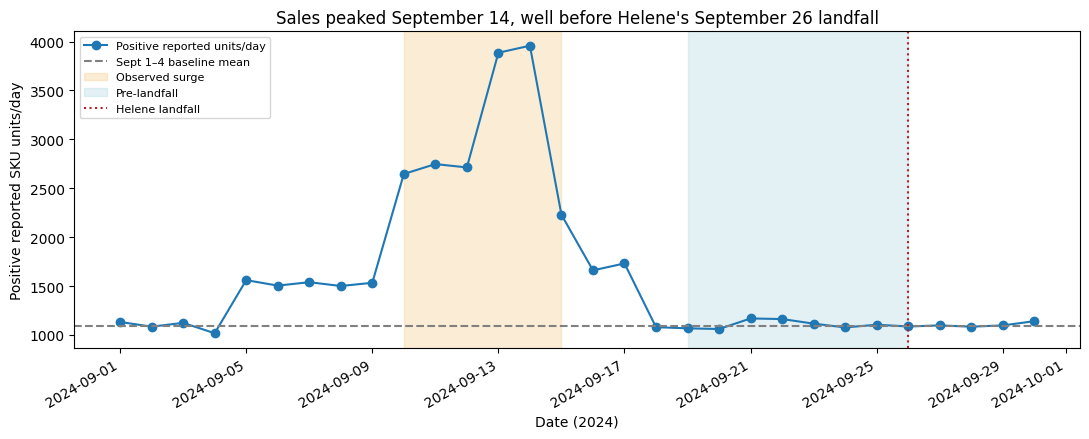

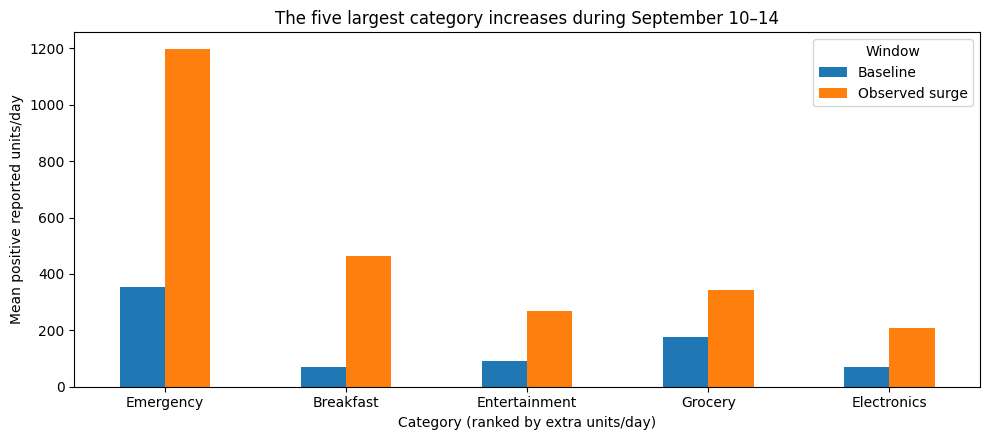

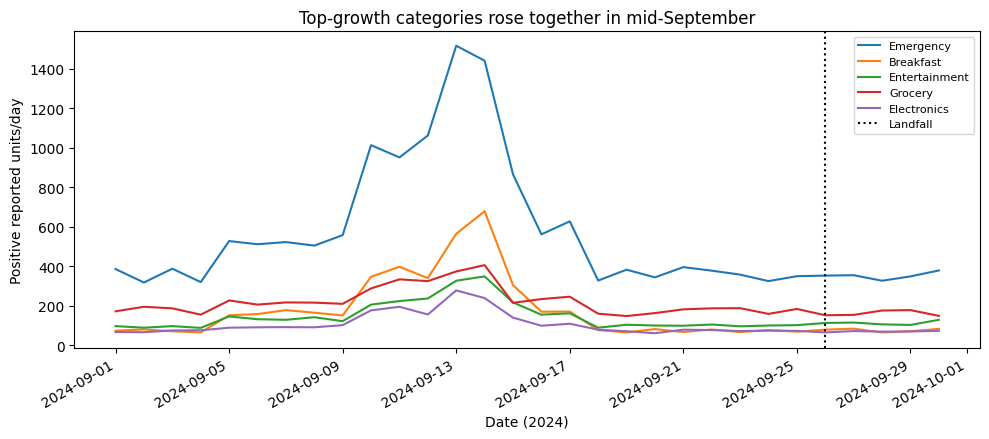

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(q1_daily.index, q1_daily, marker="o", label="Positive reported units/day")
ax.axhline(q1_base, color="gray", linestyle="--", label="Sept 1–4 baseline mean")
for label, color in [("Observed surge", "#f3b85b"), ("Pre-landfall", "#93c9d8")]:
    start, end = q1_windows[label]
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1), alpha=.25, color=color, label=label)
ax.axvline(pd.Timestamp("2024-09-26"), color="firebrick", linestyle=":", label="Helene landfall")
ax.set(title="Sales peaked September 14, well before Helene's September 26 landfall", xlabel="Date (2024)", ylabel="Positive reported SKU units/day")
ax.legend(fontsize=8); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

ax = q1_top5[["Baseline", "Observed surge"]].plot.bar(figsize=(10, 4.5), rot=0)
ax.set(title="The five largest category increases during September 10–14", xlabel="Category (ranked by extra units/day)", ylabel="Mean positive reported units/day")
ax.legend(title="Window"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
for category in q1_top5.index:
    ax.plot(q1_categories.index, q1_categories[category], label=category)
ax.axvline(pd.Timestamp("2024-09-26"), color="black", linestyle=":", label="Landfall")
ax.set(title="Top-growth categories rose together in mid-September", xlabel="Date (2024)", ylabel="Positive reported units/day")
ax.legend(fontsize=8); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

### Q1 finding

Positive reported sales averaged **1,089 units/day on September 1–4** and **3,190 on September 10–14**, a **2.93× increase in level (+192.9%)**. The peak was September 14 at 3,958 units, 12 days before landfall. In the actual September 19–25 pre-landfall week, sales averaged **1,107.4 units/day, only 1.017× baseline (+1.7%)**. Thus there is a substantial earlier spike, but little evidence of an immediate pre-landfall surge.

The five largest increases were Emergency (+844.8 units/day; 3.40×), Breakfast (+393.3; 6.50×), Entertainment (+175.85; 2.92×), Grocery (+168.15; 1.95×), and Electronics (+138.0; 2.97×). This ranking uses absolute additional units, not percentage growth. Signed net quantities give nearly the same early multiple (2.928×); using September 1–7 as the baseline lowers it to 2.492×. The spike persists, but its size depends on the baseline. Missing dates (884 rows), heterogeneous packages, and the short baseline limit interpretation. These quantities also differ from Q3's transaction-row counts. Inventory checks in Q5 are still needed before calling the pattern genuine demand.

## Q4 — Stores and geography — Nathaniel (Nate)

I compare each store's mean positive units/day in the same three Q1 windows, then divide by that store's own baseline to avoid confusing store size with growth. The transaction-to-store join must be many-to-one and preserve rows and quantities. A complete 12-store × 30-day grid includes zero-sale days.

Distance is the great-circle (haversine) distance from the provided store coordinates to the **NHC landfall point (30.0, −83.7)** cited in Q1, in kilometers. This is a proximity proxy, not distance to the full storm track or measured local wind exposure. Tallahassee (FL-619) has no coordinates in the supplied store file: it remains in the store comparison but is excluded from distance calculations rather than assigned guessed coordinates. I report both Pearson and rank correlations for the remaining stores; these are descriptive, with only 11 locations.

In [11]:
q4_reference = stores_clean[["store_id_clean", "city", "region", "latitude", "longitude"]].copy()
assert q4_reference["store_id_clean"].is_unique
q4_joined = q1_sales.merge(q4_reference, on="store_id_clean", how="left", validate="many_to_one", indicator=True)
assert len(q4_joined) == len(q1_sales)
assert q4_joined["_merge"].eq("both").all()
assert q4_joined["quantity_clean"].sum() == q1_sales["quantity_clean"].sum()
print("Store join rows before/after:", len(q1_sales), len(q4_joined))
q4_grid = pd.MultiIndex.from_product([q4_reference["store_id_clean"], q1_days], names=["store_id_clean", "date"])
q4_daily = q4_joined.groupby(["store_id_clean", "date"])["quantity_clean"].sum().reindex(q4_grid, fill_value=0).unstack("store_id_clean")
assert q4_daily.sum().sum() == q1_daily.sum()
q4_stores = q4_reference.set_index("store_id_clean")
for label, (start, end) in q1_windows.items():
    q4_stores[label] = q4_daily.loc[start:end].mean()
assert q4_stores["Baseline"].gt(0).all()
q4_stores["surge_multiple"] = q4_stores["Observed surge"] / q4_stores["Baseline"]
q4_stores["pre_landfall_multiple"] = q4_stores["Pre-landfall"] / q4_stores["Baseline"]
lat = np.radians(pd.to_numeric(q4_stores["latitude"], errors="coerce"))
lon = np.radians(pd.to_numeric(q4_stores["longitude"], errors="coerce"))
h = np.sin((lat - np.radians(30.0))/2)**2 + np.cos(lat)*np.cos(np.radians(30.0))*np.sin((lon - np.radians(-83.7))/2)**2
q4_stores["distance_km"] = 2 * 6371.0088 * np.arcsin(np.sqrt(h.clip(0, 1)))
q4_geo = q4_stores.dropna(subset=["distance_km"])
q4_corr = pd.DataFrame([
    {"window": label, "n_stores": len(q4_geo),
     "pearson_r": q4_geo["distance_km"].corr(q4_geo[column]),
     "rank_r": q4_geo["distance_km"].rank().corr(q4_geo[column].rank())}
    for label, column in [("Observed surge", "surge_multiple"), ("Pre-landfall", "pre_landfall_multiple")]
]).set_index("window")
display(q4_stores.sort_values("distance_km").round(3))
display(q4_corr.round(3))
print("Stores excluded from distance analysis:", q4_stores.loc[q4_stores.distance_km.isna(), "city"].tolist())

Store join rows before/after: 24521 24521


,city,region,latitude,longitude,Baseline,Observed surge,Pre-landfall,surge_multiple,pre_landfall_multiple,distance_km
store_id_clean,,,,,,,,,,
FL-078,Gainesville,North,29.652,-82.325,97.50,256.2,89.429,2.628,0.917,138.200
FL-412,Jacksonville,North,30.332,-81.656,82.75,262.8,91.286,3.176,1.103,199.969
FL-105,Tampa,West,27.951,-82.457,91.50,278.6,91.714,3.045,1.002,257.960
FL-445,St. Petersburg,West,27.768,-82.640,97.75,272.8,97.000,2.791,0.992,268.815
FL-156,Daytona Beach,East,29.211,-81.023,94.25,268.8,95.571,2.852,1.014,273.290
FL-302,Lakeland,Central,28.040,-81.950,97.75,286.0,93.571,2.926,0.957,276.547
FL-239,Orlando,Central,28.538,-81.379,89.50,245.2,91.143,2.740,1.018,277.646
FL-287,Kissimmee,Central,28.292,-81.408,90.00,256.2,97.571,2.847,1.084,292.617
FL-710,Pensacola,Panhandle,30.421,-87.217,86.25,268.2,92.000,3.110,1.067,341.165


,n_stores,pearson_r,rank_r
window,,,
Observed surge,11,0.430,0.227
Pre-landfall,11,0.077,0.200


Stores excluded from distance analysis: ['Tallahassee']


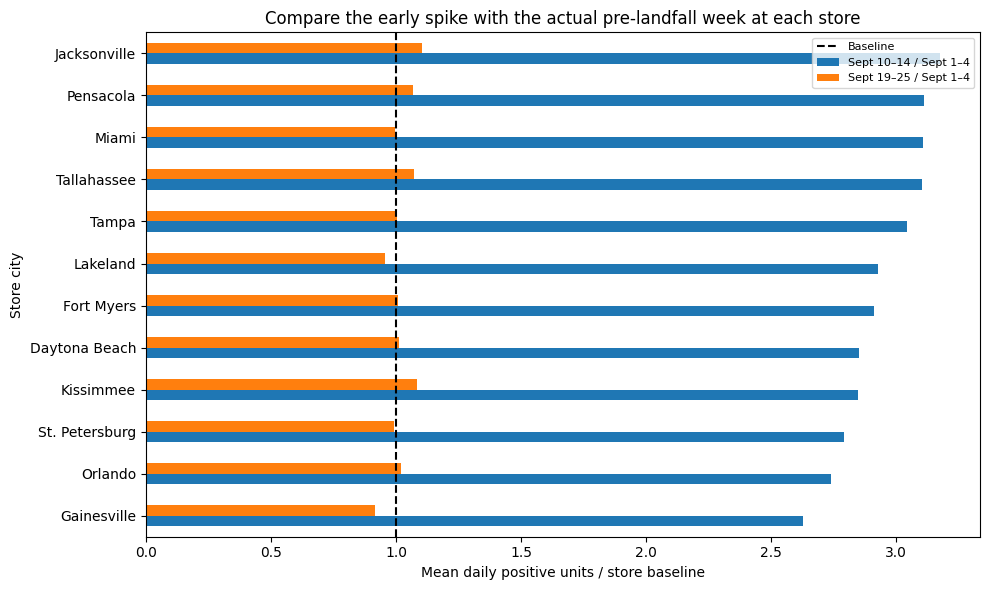

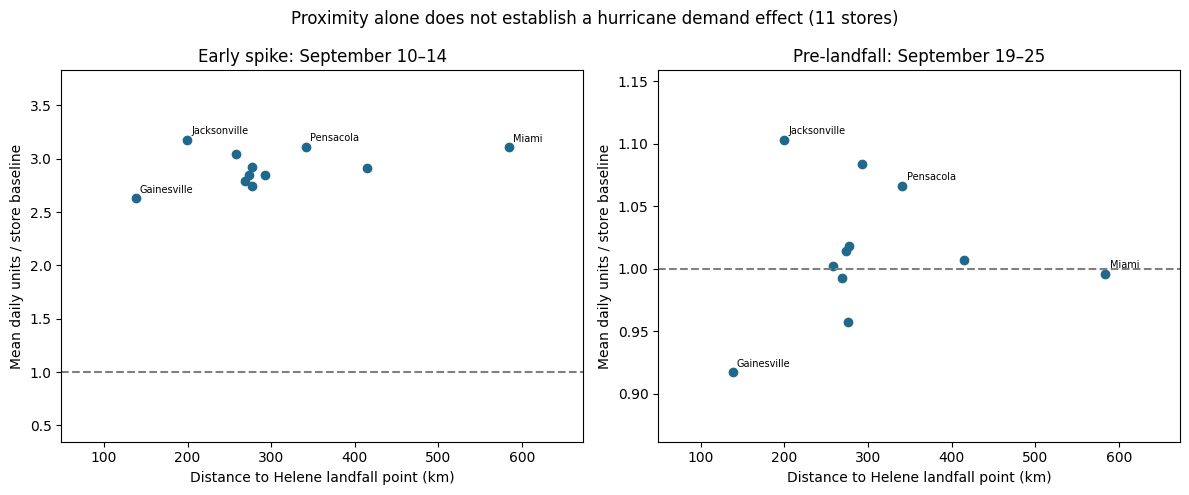

In [12]:
q4_plot = q4_stores.set_index("city")[["surge_multiple", "pre_landfall_multiple"]].sort_values("surge_multiple")
ax = q4_plot.rename(columns={"surge_multiple": "Sept 10–14 / Sept 1–4", "pre_landfall_multiple": "Sept 19–25 / Sept 1–4"}).plot.barh(figsize=(10, 6))
ax.axvline(1, color="black", linestyle="--", label="Baseline")
ax.set(title="Compare the early spike with the actual pre-landfall week at each store", xlabel="Mean daily positive units / store baseline", ylabel="Store city")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, column, title in zip(axes, ["surge_multiple", "pre_landfall_multiple"], ["Early spike: September 10–14", "Pre-landfall: September 19–25"]):
    ax.scatter(q4_geo["distance_km"], q4_geo[column], color="#21688D")
    # Label selected reference stores to keep the crowded middle readable.
    for store, row in q4_geo.loc[["FL-078", "FL-412", "FL-710", "FL-330"]].iterrows():
        ax.annotate(row["city"], (row["distance_km"], row[column]), fontsize=7, xytext=(3, 4), textcoords="offset points")
    ax.axhline(1, color="gray", linestyle="--")
    ax.set(title=title, xlabel="Distance to Helene landfall point (km)", ylabel="Mean daily units / store baseline")
    ax.margins(x=.2, y=.3)
fig.suptitle("Proximity alone does not establish a hurricane demand effect (11 stores)")
fig.tight_layout(); plt.show()

### Q4 finding

All 12 stores share the early spike: September 10–14 averages range from **2.63× baseline in Gainesville to 3.18× in Jacksonville**. The actual September 19–25 pre-landfall ratios are much smaller, **0.92×–1.10×**. The validated store join preserves all **24,521 dated positive-quantity rows** and their total units.

Among 11 stores with coordinates, distance versus early-spike growth has **Pearson r = +0.430** (rank correlation +0.227); distance versus pre-landfall growth has **r = +0.077** (rank correlation +0.200). These results do not support a pattern of larger increases nearer landfall: that would require a negative association. Gainesville, the closest measured store (138 km), has a smaller early ratio than Miami, the farthest (584 km; 3.11×).

This is a descriptive comparison, not a causal or significance claim. Tallahassee's missing coordinates remove a potentially important nearby store, landfall distance does not measure local weather or the full track, and there are only 11 usable locations. The early spike is geographically broad and predates landfall by almost two weeks. For planning, do not allocate extra stock solely using distance or this historical spike; combine local forecasts with Q5's inventory checks.